Name: Yeong Yi Feng Cayden
Title: Analyzing the Relationship Between Where Residents Live and Their Choice of Public Transport in Singapore

Intro:
Singapore's Green Plan 2030 aims to have 75% of all peak-hour trips taken via public transport. Achieving this target requires understanding the
factors that influence commuters' modal choices. This project investigates whether a resident's residential location has a significant relationship
with their likelihood of choosing public transport for their commute. By identifying residential profiles with lower public transport adoption,
this study seeks to inform more targeted and effective policy interventions.

Research questions:
What is the current baseline public transport usage rate across Singapore's planning areas?
Is there a relationship between the predominant housing type in a planning area and its public transport usage rate?
How does household income correlate with public transport usage across planning areas?
Which planning areas have the largest gap between current public transport usage and the Green Plan 2030 target of 75%?

Datasets:
Dataset1: Employed Residents Aged 15 Years and Over by Planning Area of Residence and Usual Mode of Transport to Work (Census of Population 2020)
https://data.gov.sg/datasets?query=Employed+Residents+Aged+15+Years+and+Over+by+Planning+Area+of+Residence+and+Usual+Mode+of+Transport+to+Work+(Census+of+Population+2020)&resultId=d_1f8f5ec7201964e365c77551cab99503
Resident Households by Planning Area of Residence and Type of Dwelling (Census of Population 2020)
https://data.gov.sg/datasets?query=Resident+Households+by+Planning+Area+of+Residence+and+Type+of+Dwelling+(Census+of+Population+2020)&resultId=d_388f9c61f437a588b47b008a012d13fa
Dataset3: Resident Households by Planning Area of Residence and Monthly Household Income from Work (Census Of Population 2020)
https://data.gov.sg/datasets?sort=updatedAt&query=Resident+Households+by+Planning+Area+of+Residence+and+Monthly+Household+Income+from+Work+(Census+of+Population+2020)&resultId=d_2d6793de474551149c438ba349a108fd
Dataset4: Public Transport Utilisation - Average Public Transport Ridership
https://data.gov.sg/datasets?query=Public+Transport+Utilisation+-+Average+Public+Transport+Ridership&resultId=d_75248cf2fbf340de6a746dc91ec9223c

In [53]:
#import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [54]:
#load data
df_transport = pd.read_csv('EmployedResidentsAged15YearsandOverbyPlanningAreaofResidenceandUsualModeofTransporttoWorkCensusofPopulation2020.csv')
df_dwelling = pd.read_csv('ResidentHouseholdsbyPlanningAreaofResidenceandTypeofDwellingCensusofPopulation2020.csv')
df_income = pd.read_csv('ResidentHouseholdsbyPlanningAreaofResidenceandMonthlyHouseholdIncomefromWorkCensusOfPopulation2020.csv')
df_trend = pd.read_csv('PublicTransportUtilisationAveragePublicTransportRidership.csv')

In [96]:
#data cleaning
pt_cols = ['PublicBusOnly', 'Rail_MRT_LRT_Only', 'Rail_MRT_LRT_andPublicBusOnly', 'CombinationofRail_MRT_LRT_and_orPublicBus_withOtherModes']
df_transport[pt_cols] = df_transport[pt_cols].apply(pd.to_numeric, errors='coerce')
df_transport['Total'] = pd.to_numeric(df_transport['Total'], errors='coerce')
df_transport['PT_Total'] = df_transport[pt_cols].sum(axis=1)
df_transport['PT_Share'] = (df_transport['PT_Total'] / df_transport['Total']) * 100
df_transport_clean = df_transport[['Number', 'Total', 'PT_Share']].copy()
df_transport_clean.rename(columns={'Number': 'Planning_Area', 'Total': 'Total_Residents'}, inplace=True)
# REMOVE THE "Total" ROW
df_transport_clean = df_transport_clean[df_transport_clean['Planning_Area'] != 'Total']
# Clean Dwelling
numeric_cols = ['Total', 'HDBDwellings_Total', 'CondominiumsandOtherApartments', 'LandedProperties']
df_dwelling[numeric_cols] = df_dwelling[numeric_cols].apply(pd.to_numeric, errors='coerce')
df_dwelling['HDB_Pct'] = (df_dwelling['HDBDwellings_Total'] / df_dwelling['Total']) * 100
df_dwelling['Private_Pct'] = ((df_dwelling['CondominiumsandOtherApartments'] + df_dwelling['LandedProperties']) / df_dwelling['Total']) * 100
df_dwelling_clean = df_dwelling[['Number', 'Total', 'HDB_Pct', 'Private_Pct']].copy()
df_dwelling_clean.rename(columns={'Number': 'Planning_Area', 'Total': 'Total_HH_Dwelling'}, inplace=True)
# REMOVE THE "Total" ROW
df_dwelling_clean = df_dwelling_clean[df_dwelling_clean['Planning_Area'] != 'Total']
# Clean Income
income_cols = ['Below_1_000', '1_000_1_999', '2_000_2_999', '3_000_3_999', '4_000_4_999', '5_000_5_999', '6_000_6_999', '7_000_7_999', '8_000_8_999', '9_000_9_999', '10_000_10_999', '11_000_11_999', '12_000_12_999', '13_000_13_999', '14_000_14_999', '15_000_17_499', '17_500_19_999', '20_000andOver']
df_income[income_cols] = df_income[income_cols].apply(pd.to_numeric, errors='coerce')
df_income['Total'] = pd.to_numeric(df_income['Total'], errors='coerce')
midpoints = [500, 1500, 2500, 3500, 4500, 5500, 6500, 7500, 8500, 9500, 10500, 11500, 12500, 13500, 14500, 16250, 18750, 22000]
weighted_sum = pd.Series(0, index=df_income.index)
for col, mid in zip(income_cols, midpoints):
    weighted_sum += df_income[col] * mid
df_income['Avg_Income'] = weighted_sum / df_income['Total']
df_income_clean = df_income[['Number', 'Total', 'Avg_Income']].copy()
df_income_clean.rename(columns={'Number': 'Planning_Area', 'Total': 'Total_HH_Income'}, inplace=True)
# REMOVE THE "Total" ROW
df_income_clean = df_income_clean[df_income_clean['Planning_Area'] != 'Total']
# Merge
df_merged = pd.merge(df_transport_clean, df_dwelling_clean, on='Planning_Area', how='inner')
df_merged = pd.merge(df_merged, df_income_clean, on='Planning_Area', how='inner')
# Clean Trend
df_trend['ridership'] = pd.to_numeric(df_trend['ridership'], errors='coerce')
df_trend_pivot = df_trend.pivot(index='year', columns='mode', values='ridership').reset_index()
df_trend_pivot['Total'] = df_trend_pivot['MRT'] + df_trend_pivot['LRT'] + df_trend_pivot['Bus']
# Save data
df_merged.to_csv('merged_clean_data.csv', index=False)
df_trend_pivot.to_csv('trend_clean_data.csv', index=False)

print("Summary Statistics:")
print("================================")
print(f"Min PT Share: {np.min(df_merged['PT_Share']):.1f}%")
print(f"Max PT Share: {np.max(df_merged['PT_Share']):.1f}%")
print(f"Mean PT Share: {np.mean(df_merged['PT_Share']):.1f}%")
print(f"Median PT Share: {np.median(df_merged['PT_Share']):.1f}%")
print(f"Std Dev PT Share: {np.std(df_merged['PT_Share']):.1f}%")

Summary Statistics:
Min PT Share: 28.9%
Max PT Share: 63.1%
Mean PT Share: 54.4%
Median PT Share: 57.9%
Std Dev PT Share: 9.1%


# Data Preparation

### Data Sources
This analysis uses four datasets from data.gov.sg, all from the Census of Population 2020:

1. **Transport Dataset:** Employed Residents Aged 15 Years and Over by Planning Area of Residence and Usual Mode of Transport to Work
   - Contains the number of employed residents by planning area and their mode of transport to work
   - Used to calculate public transport share per planning area

2. **Dwelling Dataset:** Resident Households by Planning Area of Residence and Type of Dwelling
   - Contains the distribution of housing types (HDB, condominiums, landed properties) by planning area
   - Used to calculate HDB and private housing percentages

3. **Income Dataset:** Resident Households by Planning Area of Residence and Monthly Household Income from Work
   - Contains household income distribution by planning area
   - Used to calculate average household income per planning area

4. **Trend Dataset:** Public Transport Utilisation - Average Public Transport Ridership
   - Contains average daily ridership for MRT, LRT, and public buses from 1995 to 2024
   - Used to show the national ridership trend

### Data Cleaning Process

The following steps were performed to clean and prepare the data for analysis:

**1. Transport Dataset**
- Defined public transport as: Public Bus only, MRT/LRT only, MRT/LRT + Public Bus, and combinations with other modes
- Calculated total public transport users per planning area by summing these columns
- Computed public transport share as: (PT_Total / Total Residents) × 100
- Removed the "Total" summary row
- Kept only: Planning_Area, Total_Residents, PT_Share

**2. Dwelling Dataset**
- Converted all numeric columns to proper data types using pd.to_numeric()
- Calculated HDB percentage as: (HDBDwellings_Total / Total) × 100
- Calculated private percentage as: ((Condominiums + Landed) / Total) × 100
- Removed the "Total" summary row
- Kept only: Planning_Area, Total_HH_Dwelling, HDB_Pct, Private_Pct

**3. Income Dataset**
- Converted all income columns to proper data types using pd.to_numeric()
- Used midpoints for each income bracket to calculate weighted average income
- Removed the "Total" summary row
- Kept only: Planning_Area, Total_HH_Income, Avg_Income

**4. Merging**
- All three datasets were merged on "Planning_Area" using an inner join
- This resulted in a single dataset with 31 planning areas (all areas except "Total")

**5. Trend Dataset**
- Pivoted the data so each mode (MRT, LRT, Bus) became a separate column
- Calculated total ridership as: MRT + LRT + Bus
- This created a time-series dataset from 1995 to 2024

### Final Cleaned Dataset

After cleaning and merging, the final dataset contains 31 rows (one per planning area) and 8 columns:

| Column | Description |
| :--- | :--- |
| Planning_Area | Name of the planning area |
| Total_Residents | Number of employed residents aged 15+ |
| PT_Share | Percentage of residents using public transport (%) |
| Total_HH_Dwelling | Total number of households |
| HDB_Pct | Percentage of households in HDB flats (%) |
| Private_Pct | Percentage of households in private housing (%) |
| Total_HH_Income | Total number of households (income data) |
| Avg_Income | Weighted average household income ($) |

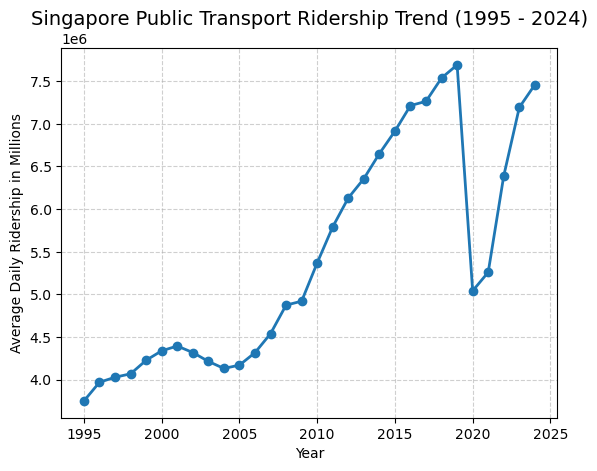

In [65]:
plt.plot(df_trend_pivot['year'], df_trend_pivot['Total'], 
         marker='o', linestyle='-', linewidth=2)

plt.title('Singapore Public Transport Ridership Trend (1995 - 2024)', fontsize=14)
plt.xlabel('Year')
plt.ylabel('Average Daily Ridership in Millions')
plt.grid(True, linestyle='--', alpha=0.6)

# National Public Transport Usage Trend

To provide context for our analysis, we first examine the long-term trend in public transport ridership in Singapore. The Green Plan 2030 has set an ambitious target of achieving a 75% public transport modal share during peak hours. Understanding the national trajectory helps us benchmark the performance of individual planning areas, which we will analyze in the subsequent sections.

**Figure 1:** Average daily public transport ridership (MRT, LRT, and Bus combined) from 1995 to 2024.
*Data source: Land Transport Authority via data.gov.sg*

### Key Observations

1. **Long-term Growth:** Public transport ridership has grown steadily from approximately 3.8 million daily trips in 1995 to over 7.4 million in 2024.

2. **COVID-19 Impact:** A sharp decline occurred in 2020 due to the COVID-19 pandemic, with ridership dropping to around 5.0 million daily trips.

3. **Recovery:** Ridership has been recovering since 2021 and is approaching pre-pandemic levels, reaching approximately 7.4 million in 2024.

4. **Context for Analysis:** This national trend shows that public transport usage is increasing overall. However, as we will see in the following sections, this growth is not uniform across all planning areas.

**Important Note:** While ridership volume is not directly comparable to the 75% modal share target (which measures the percentage of all motorized trips taken by public transport), this upward trend reflects increasing reliance on public transport overall. The subsequent analysis will examine modal share percentages at the planning area level using Census 2020 data.

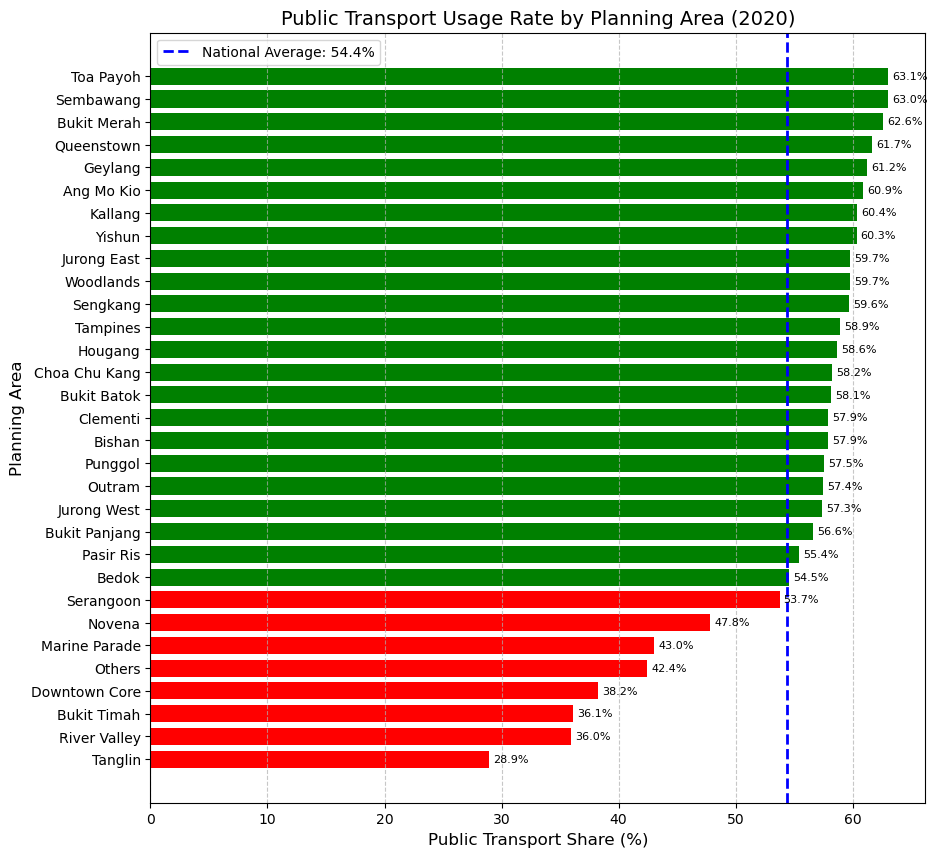

In [83]:
# Sort by PT_Share (lowest first)
df_sorted = df_merged.sort_values('PT_Share', ascending=True)
national_avg = df_merged['PT_Share'].mean()

# Color: green if above average, red if below
colors = ['green' if x >= national_avg else 'red' for x in df_sorted['PT_Share']]

fig, ax = plt.subplots(figsize=(10, 10))

# Create horizontal bar chart
bars = ax.barh(df_sorted['Planning_Area'], df_sorted['PT_Share'], 
               color=colors, linewidth=0.5, height=0.75)

# Use ax.bar_label to add value labels
ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=8)

# Vertical line for national average
ax.axvline(x=national_avg, color='blue', linestyle='--', linewidth=2,
           label=f'National Average: {national_avg:.1f}%')

ax.set_title('Public Transport Usage Rate by Planning Area (2020)', fontsize=14)
ax.set_xlabel('Public Transport Share (%)', fontsize=12)
ax.set_ylabel('Planning Area', fontsize=12)
ax.grid(axis='x', linestyle='--', alpha=0.7)
ax.legend()

Before investigating what factors influence public transport choice, we first establish a baseline. The horizontal bar chart below shows the percentage of employed residents who use public transport (MRT/LRT and/or public bus) to commute to work, broken down by their planning area of residence.

The red dashed line represents the national average public transport usage rate across all planning areas. Areas with bars to the right of the line have higher-than-average public transport adoption, while areas to the left are lagging behind.

**Figure 2:** Public transport share by planning area of residence.
*Data source: Census of Population 2020, Singapore Department of Statistics*

### Key Observations

1. **National Average:** The national average public transport share is **54.4%**, which is well below the Green Plan 2030 target of 75%.

2. **Highest Performers (Top 5):** 
   - **Toa Payoh:** 63.1%
   - **Sembawang:** 63.0%
   - **Bukit Merah:** 62.6%
   - **Queenstown:** 61.7%
   - **Geylang:** 61.2%

3. **Lowest Performers (Bottom 5):**
   - **Tanglin:** 28.9%
   - **River Valley:** 36.0%
   - **Bukit Timah:** 36.1%
   - **Downtown Core:** 38.2%
   - **Others:** 42.4%

4. **Variation:** There is significant variation across planning areas, ranging from **28.9%** (Tanglin) to **63.1%** (Toa Payoh) – a difference of over **34 percentage points**. This suggests that location-specific factors strongly influence transport choices.

5. **Areas Above National Average:** **23 out of 31** planning areas are above the national average of 54.4%. The remaining **8 areas** are below average.

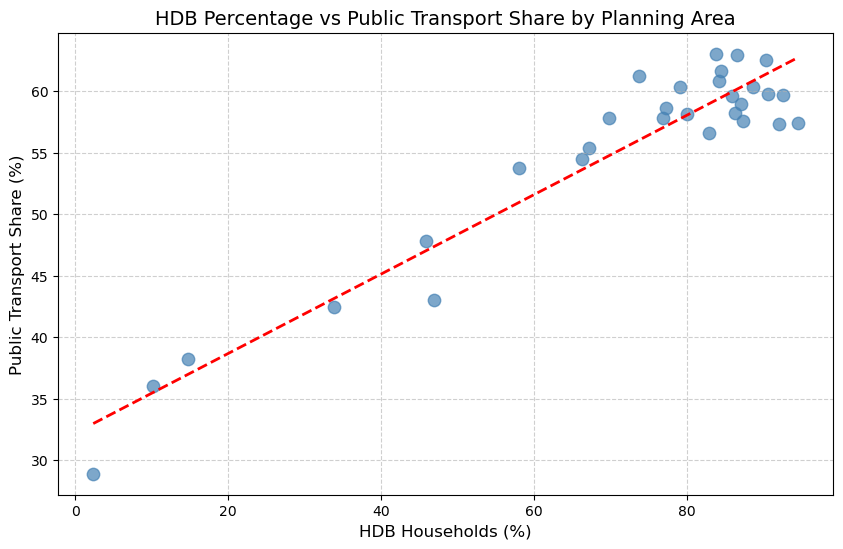

In [87]:
fig, ax = plt.subplots(figsize=(10, 6))

# Seaborn regplot with trend line (no shaded area, no point labels)
sns.regplot(x='HDB_Pct', y='PT_Share', data=df_merged,
            scatter_kws={'color': 'steelblue', 'alpha': 0.7, 's': 80},
            line_kws={'color': 'red', 'linestyle': '--', 'linewidth': 2},
            ci=None,  # <-- Removes shaded confidence interval
            ax=ax)

# Add labels and title
ax.set_title('HDB Percentage vs Public Transport Share by Planning Area', fontsize=14)
ax.set_xlabel('HDB Households (%)', fontsize=12)
ax.set_ylabel('Public Transport Share (%)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.6)

This scatter plot examines whether planning areas with a higher proportion of HDB housing tend to have higher public transport usage. We hypothesize that areas with more public housing (HDB) are better served by public transport infrastructure and have residents who are more likely to use public transport.

The red dashed line represents the trend line showing the overall relationship between HDB percentage and public transport share.

**Figure 3:** Relationship between HDB percentage and public transport share by planning area.
*Data source: Census of Population 2020, Singapore Department of Statistics*

### Key Observations

1. **Strong Positive Correlation:** There is a very strong positive relationship between HDB percentage and public transport share, with a correlation coefficient of **0.952**. Areas with higher HDB proportions tend to have significantly higher public transport usage.

2. **Low HDB Areas (< 50%):** Areas with low HDB percentage have consistently low PT share:
   - **Tanglin:** 2.4% HDB → 28.9% PT
   - **Bukit Timah:** 10.1% HDB → 36.1% PT
   - **Downtown Core:** 14.8% HDB → 38.2% PT

3. **High HDB Areas (> 80%):** 15 planning areas have HDB above 80%, with PT share ranging from **56.6%** (Bukit Panjang) to **63.1%** (Toa Payoh). All are above the national average of 54.4%.

4. **Clear Threshold:** Areas with HDB percentage below 50% have PT share below 48%. Areas with HDB percentage above 80% have PT share above 56%. This clear threshold suggests that public housing estates are significantly better served by public transport infrastructure.

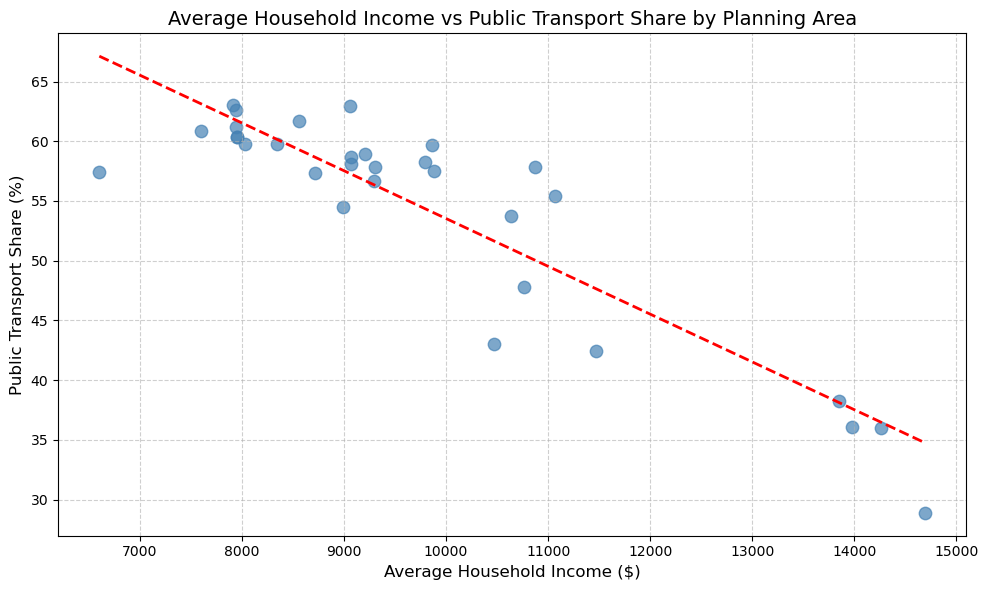


SUMMARY FOR MARKDOWN


In [93]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(x='Avg_Income', y='PT_Share', data=df_merged,
            scatter_kws={'color': 'steelblue', 'alpha': 0.7, 's': 80},
            line_kws={'color': 'red', 'linestyle': '--', 'linewidth': 2},
            ci=None,  # Remove shaded confidence interval
            ax=ax)

ax.set_title('Average Household Income vs Public Transport Share by Planning Area', fontsize=14)
ax.set_xlabel('Average Household Income ($)', fontsize=12)
ax.set_ylabel('Public Transport Share (%)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Print summary for markdown
print("\n" + "="*50)
print("SUMMARY FOR MARKDOWN")
print("="*50)

correlation = df_merged['Avg_Income'].corr(df_merged['PT_Share'])


This scatter plot examines the relationship between average household income and public transport usage across planning areas. We hypothesize that higher-income areas may have lower public transport usage due to higher car ownership rates and greater ability to afford private transport.

The red dashed line represents the trend line showing the overall relationship between income and public transport share.

**Figure 4:** Relationship between average household income and public transport share by planning area.
*Data source: Census of Population 2020, Singapore Department of Statistics*

### Key Observations

1. **Strong Negative Correlation:** There is a very strong negative relationship between average household income and public transport share, with a correlation coefficient of **-0.901**. As income increases, PT share tends to decrease significantly.

2. **Low Income Areas (< $8,000):** Areas with average income below $8,000 have consistently high PT share above 57%:
   - **Toa Payoh:** $7,915 → 63.1% PT
   - **Bukit Merah:** $7,944 → 62.6% PT
   - **Geylang:** $7,944 → 61.2% PT
   - **Ang Mo Kio:** $7,594 → 60.9% PT

3. **High Income Areas (> $10,000):** Areas with average income above $10,000 have consistently low PT share:
   - **Tanglin:** $14,694 → 28.9% PT
   - **River Valley:** $14,266 → 36.0% PT
   - **Bukit Timah:** $13,982 → 36.1% PT
   - **Downtown Core:** $13,849 → 38.2% PT

4. **Clear Pattern:** Areas with income below $8,000 have PT share above 57%. Areas with income above $10,000 generally have PT share below 48%. This suggests that higher-income residents are more likely to own cars and less likely to use public transport.

5. **Exception:** **Pasir Ris** has income above $10,000 ($11,072) but relatively high PT share (55.4%) – possibly due to good MRT connectivity.

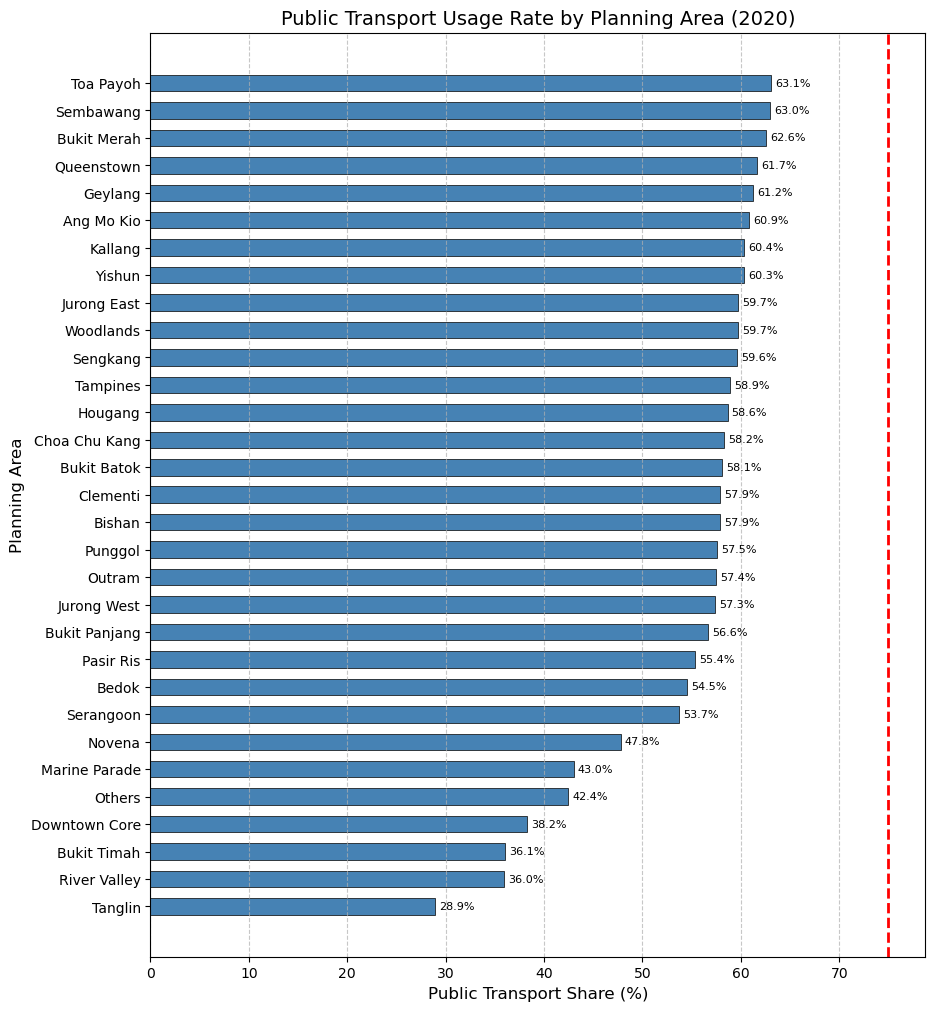

In [91]:
df_sorted = df_merged.sort_values('PT_Share', ascending=True)

fig, ax = plt.subplots(figsize=(10, 12))

# Create horizontal bar chart
bars = ax.barh(df_sorted['Planning_Area'], df_sorted['PT_Share'], 
               color='steelblue', edgecolor='black', linewidth=0.5,
               height=0.6)

# Add value labels on each bar
ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=8)

# Add vertical line at 75%
ax.axvline(x=75, color='red', linestyle='--', linewidth=2,
           label='Green Plan 2030 Target (75%)')

# Add labels and title
ax.set_title('Public Transport Usage Rate by Planning Area (2020)', fontsize=14)
ax.set_xlabel('Public Transport Share (%)', fontsize=12)
ax.set_ylabel('Planning Area', fontsize=12)

# Add grid on x-axis
ax.grid(axis='x', linestyle='--', alpha=0.7)

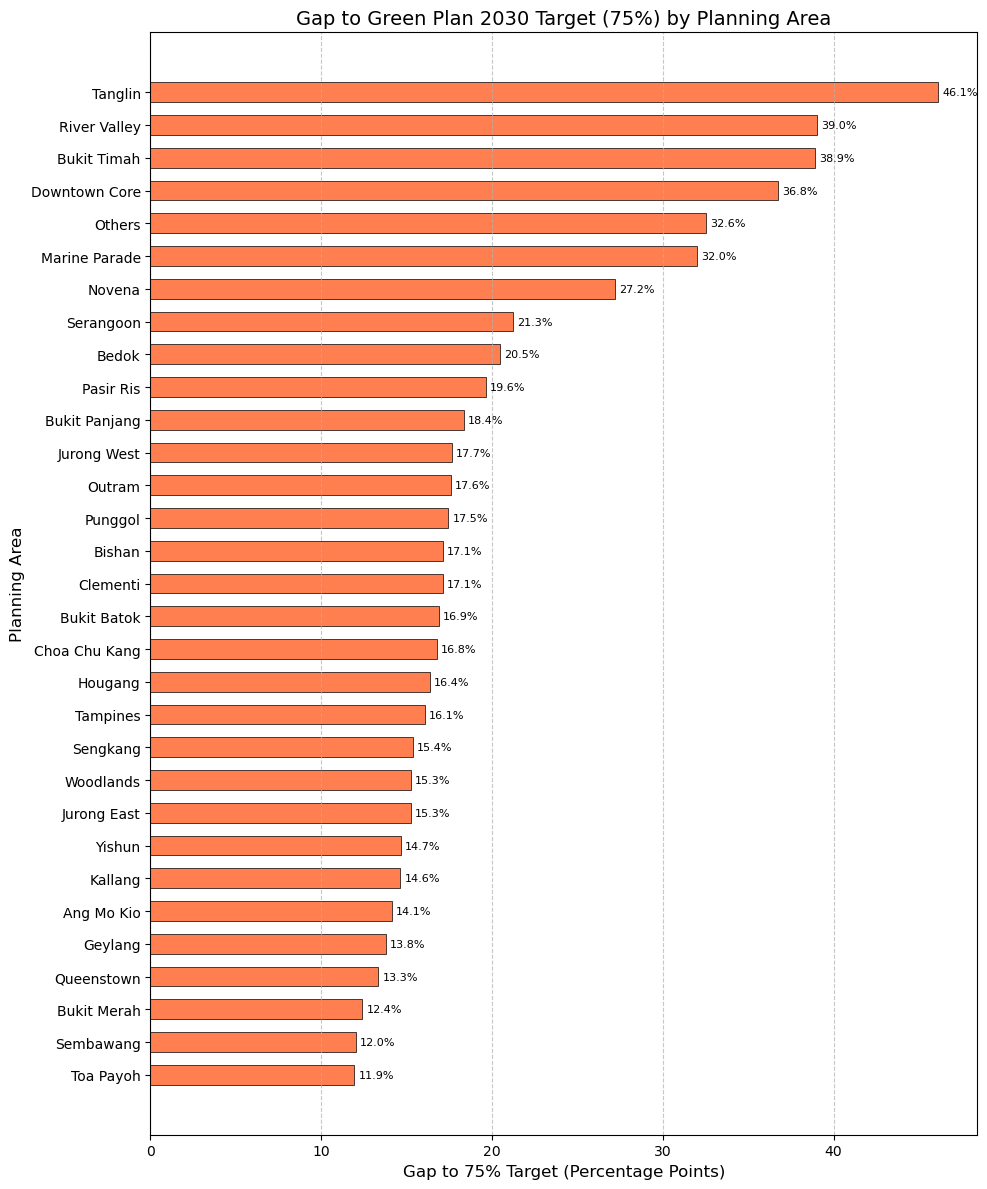

In [94]:
df_merged['Gap_to_75'] = np.maximum(75 - df_merged['PT_Share'], 0)

# Sort by gap (smallest first so largest appears at top)
df_gap_sorted = df_merged.sort_values('Gap_to_75', ascending=True)

fig, ax = plt.subplots(figsize=(10, 12))

# Create horizontal bar chart
bars = ax.barh(df_gap_sorted['Planning_Area'], df_gap_sorted['Gap_to_75'], 
               color='coral', edgecolor='black', linewidth=0.5,
               height=0.6)

# Add value labels on each bar
ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=8)

# Add labels and title
ax.set_title('Gap to Green Plan 2030 Target (75%) by Planning Area', fontsize=14)
ax.set_xlabel('Gap to 75% Target (Percentage Points)', fontsize=12)
ax.set_ylabel('Planning Area', fontsize=12)

# Add grid on x-axis
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

The Green Plan 2030 sets an ambitious target of 75% of peak-period trips to be taken via public transport. To identify priority areas for intervention, we calculate the shortfall between each planning area's current public transport share and the 75% target.

The horizontal bar chart below shows the gap (in percentage points) for each planning area. Areas with larger gaps require the most attention from policymakers.

**Figure 5:** Gap to 75% Green Plan target by planning area.
*Data source: Census of Population 2020, Singapore Department of Statistics*

## Key Observations

1. **All Areas Below Target:** Every planning area is below the 75% target, with gaps ranging from **11.9%** (Toa Payoh) to **46.1%** (Tanglin).

2. **Smallest Gaps (Closest to Target):** The areas closest to the 75% target are:
   - **Toa Payoh:** Gap of 11.9%
   - **Sembawang:** Gap of 12.0%
   - **Bukit Merah:** Gap of 12.4%
   - **Queenstown:** Gap of 13.3%
   - **Geylang:** Gap of 13.8%

3. **Largest Gaps (Furthest from Target):** The areas furthest from the target are:
   - **Tanglin:** Gap of 46.1%
   - **River Valley:** Gap of 39.0%
   - **Bukit Timah:** Gap of 38.9%
   - **Downtown Core:** Gap of 36.8%
   - **Marine Parade:** Gap of 32.0%

4. **Priority Areas:** The areas with the largest gaps (Tanglin, River Valley, Bukit Timah, Downtown Core) are predominantly high-income, private housing areas. These should be the top priority for policy interventions.

5. **National Context:** With all areas below the 75% target and a national average of only 54.4%, significant effort is needed across the entire country to achieve the Green Plan 2030 goal.

## Conclusions and Recommendations

### Summary of Findings

This study analyzed the relationship between residential location and public transport choice in Singapore using Census 2020 data across 31 planning areas.

**RQ1 - Baseline PT Share:**
- National average: **54.4%** – well below the 75% Green Plan target.
- PT share ranges from **28.9%** (Tanglin) to **63.1%** (Toa Payoh).
- **23 out of 31** areas are above the national average.

**RQ2 - Housing Type:**
- Strong positive correlation (**0.952**) between HDB percentage and PT share.
- Areas with HDB > 80% have PT share above 56%; areas with HDB < 50% have PT share below 48%.

**RQ3 - Income:**
- Strong negative correlation (**-0.901**) between income and PT share.
- Low-income areas (< $8,000) have PT share above 57%; high-income areas (> $10,000) have PT share below 48%.

**RQ4 - Gap to 75% Target:**
- All 31 areas are below the 75% target.
- Largest gaps: Tanglin (46.1%), River Valley (39.0%), Bukit Timah (38.9%), Downtown Core (36.8%).

### Policy Recommendations

1. **Improve connectivity** in areas with the largest gaps (Tanglin, River Valley, Bukit Timah, Downtown Core) through new MRT lines, better bus services, and last-mile infrastructure.

2. **Implement car-lite measures** in high-income areas: reduced parking, congestion pricing, and better cycling/walking infrastructure.

3. **Learn from best practices** in high-performing areas (Toa Payoh, Sembawang, Bukit Merah) and replicate successful strategies.

4. **Targeted campaigns** in high-income areas to promote public transport as a viable alternative to driving.

### Limitations

- Uses Census 2020 data; post-COVID patterns may have shifted.
- Analysis at planning area level; individual factors (age, car ownership) not captured.
- Focuses on commuting trips only.

### Future Work

- Incorporate more recent data (e.g., Household Travel Survey 2023).
- Analyze specific MRT station catchment areas for granular insights.
- Include workplace location to analyze commute distance.

### Final Remarks

This analysis shows that residential location – particularly housing type and income – is strongly associated with public transport choice. Achieving the 75% Green Plan target will require targeted interventions in high-income, low-PT-share areas. The findings provide a clear roadmap for policymakers to prioritize resources effectively.